# Guide pour l'Appel à une API Hugging Face pour la Segmentation d'Images

Bienvenue ! Ce notebook a pour but de vous guider pas à pas dans l'utilisation de l'API d'inférence de Hugging Face pour effectuer de la segmentation d'images. La segmentation d'images consiste à attribuer une étiquette (comme "cheveux", "vêtement", "arrière-plan") à chaque pixel d'une image.

Nous allons :
1. Comprendre ce qu'est une API et comment s'y connecter.
2. Envoyer une image à un modèle de segmentation hébergé sur Hugging Face.
3. Récupérer et interpréter les résultats.
4. Visualiser les masques de segmentation.
5. Étendre cela pour traiter plusieurs images.

## 1. Configuration Initiale et Importations

Commençons par importer les bibliothèques Python nécessaires. Nous aurons besoin de :
- `os` pour interagir avec le système de fichiers (lister les images).
- `requests` pour effectuer des requêtes HTTP vers l'API.
- `PIL (Pillow)` pour manipuler les images.
- `matplotlib.pyplot` pour afficher les images et les masques.
- `numpy` pour la manipulation des tableaux (les images sont des tableaux de pixels).
- `tqdm.notebook` pour afficher une barre de progression (utile pour plusieurs images).
- `base64` et `io` pour décoder les masques renvoyés par l'API.

### Imports

In [30]:
import os
import requests
import asyncio
import aiohttp
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
from tqdm.notebook import tqdm
import base64
import io
from dotenv import dotenv_values
import time
import mimetypes


### Variables de Configuration

Nous devons définir quelques variables :
- `image_dir`: Le chemin vers le dossier contenant vos images. **Assurez-vous de modifier ce chemin si nécessaire.**
- `max_images`: Le nombre maximum d'images à traiter (pour ne pas surcharger l'API ou attendre trop longtemps).
- `api_token`: Votre jeton d'API Hugging Face. **IMPORTANT : Gardez ce jeton secret !**

**Comment obtenir un token API Hugging Face ?**
1. Créez un compte sur [huggingface.co](https://huggingface.co/).
2. Allez dans votre profil -> Settings -> Access Tokens.
3. Créez un nouveau token (par exemple, avec le rôle "read").
4. Copiez ce token ici.

In [31]:
# TODO: Modifiez ces valeurs selon votre configuration
image_dir = "./IMG"  # Exemple : si vous êtes sur Colab et avez uploadé un dossier
max_images = 3  # Commençons avec peu d'images

# IMPORTANT: Remplacez "VOTRE_TOKEN_HUGGING_FACE_ICI" par votre véritable token API.
# Ne partagez jamais votre token publiquement.

# Chargement des variables d'environnement depuis le fichier .env
config = dotenv_values(".env")  
api_token = config['SECRET_KEY']


# Créons le dossier d'images s'il n'existe pas (pour l'exemple)
if not os.path.exists(image_dir):
    os.makedirs(image_dir)
    print(f"Dossier '{image_dir}' créé. Veuillez y ajouter des images .jpg ou .png.")
else:
    print(f"Dossier '{image_dir}' existant.")

if api_token == "VOTRE_TOKEN_HUGGING_FACE_ICI":
    print("\nATTENTION : Vous devez remplacer 'VOTRE_TOKEN_HUGGING_FACE_ICI' par votre token API personnel.")

Dossier './IMG' existant.


## 2. Comprendre l'API d'Inférence Hugging Face

L'API d'inférence permet d'utiliser des modèles hébergés sur Hugging Face sans avoir à les télécharger ou à gérer l'infrastructure.

- **Modèle utilisé** : Nous allons utiliser le modèle `sayeed99/segformer_b3_clothes`, spécialisé dans la segmentation de vêtements et de parties du corps.
- **URL de l'API** : L'URL pour un modèle est généralement `https://api-inference.huggingface.co/models/NOM_DU_MODELE`.
- **Headers (En-têtes)** : Pour s'authentifier et spécifier le type de contenu, nous envoyons des en-têtes avec notre requête.
    - `Authorization`: Contient notre token API (précédé de `Bearer `).
    - `Content-Type`: Indique que nous envoyons une image au format JPEG (ou PNG selon le cas).

In [32]:
#API_URL = "https://api-inference.huggingface.co/models/sayeed99/segformer_b3_clothes" # Remplacez ... par le bon endpoint.
API_URL = "https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes"
headers = {
    "Authorization": f"Bearer {api_token}",
    # Le "Content-Type" sera ajouté dynamiquement lors de l'envoi de l'image
}

# Lister les chemins des images à traiter
# Assurez-vous d'avoir des images dans le dossier 'image_dir'!
image_paths = ['image_0.png','image_1.png','image_18.png',] # A vous de jouer !

#-------------------------------------------
# test de connexion à l'API
# def query(filename):
#     with open(filename, "rb") as f:
#         data = f.read()
#     response = requests.post(API_URL, headers={"Content-Type": "image/jpeg", **headers}, data=data)
#     return response.json()
#-------------------------------------------

output = query('./IMG/image_0.png')
print(output)

if not image_paths:
    print(f"Aucune image trouvée dans '{image_dir}'. Veuillez y ajouter des images.")
else:
    print(f"{len(image_paths)} image(s) à traiter : {image_paths}")

NameError: name 'query' is not defined

## 3. Fonctions Utilitaires pour le Traitement des Masques

Le modèle que nous utilisons (`sayeed99/segformer_b3_clothes`) renvoie des masques pour différentes classes (cheveux, chapeau, etc.). Ces masques sont encodés en base64. Les fonctions ci-dessous sont fournies pour vous aider à :
1.  `CLASS_MAPPING`: Un dictionnaire qui associe les noms de classes (ex: "Hat") à des identifiants numériques.
2.  `get_image_dimensions`: Récupérer les dimensions d'une image.
3.  `decode_base64_mask`: Décoder un masque de base64 en une image (tableau NumPy) et le redimensionner.
4.  `create_masks`: Combiner les masques de toutes les classes détectées en un seul masque de segmentation final, où chaque pixel a la valeur de l'ID de sa classe.

**Cette partie est donnée car elle est spécifique au format de sortie de ce modèle et un peu complexe pour une première approche.** Lisez-la pour comprendre son rôle, mais ne vous attardez pas sur les détails d'implémentation pour l'instant.

In [ ]:
CLASS_MAPPING = {
    "Background": 0,
    "Hat": 1,
    "Hair": 2,
    "Sunglasses": 3,
    "Upper-clothes": 4,
    "Skirt": 5,
    "Pants": 6,
    "Dress": 7,
    "Belt": 8,
    "Left-shoe": 9,
    "Right-shoe": 10,
    "Face": 11,
    "Left-leg": 12,
    "Right-leg": 13,
    "Left-arm": 14,
    "Right-arm": 15,
    "Bag": 16,
    "Scarf": 17
}

def get_image_dimensions(img_path):
    """    Get the dimensions of an image.
    Args:
        img_path (str): Path to the image.
    Returns:
        tuple: (width, height) of the image.
    """
    original_image = Image.open(img_path)
    return original_image.size

def decode_base64_mask(base64_string, width, height):
    """
    Decode a base64-encoded mask into a NumPy array.

    Args:
        base64_string (str): Base64-encoded mask.
        width (int): Target width.
        height (int): Target height.

    Returns:
        np.ndarray: Single-channel mask array.
    """
    mask_data = base64.b64decode(base64_string)
    mask_image = Image.open(io.BytesIO(mask_data))
    mask_array = np.array(mask_image)
    if len(mask_array.shape) == 3:
        mask_array = mask_array[:, :, 0]  # Take first channel if RGB
    mask_image = Image.fromarray(mask_array).resize((width, height), Image.NEAREST)
    return np.array(mask_image)

def create_masks(results, width, height):
    """
    Combine multiple class masks into a single segmentation mask.

    Args:
        results (list): List of dictionaries with 'label' and 'mask' keys.
        width (int): Target width.
        height (int): Target height.

    Returns:
        np.ndarray: Combined segmentation mask with class indices.
    """
    combined_mask = np.zeros((height, width), dtype=np.uint8)  # Initialize with Background (0)

    # Process non-Background masks first
    for result in results:
        label = result['label']
        class_id = CLASS_MAPPING.get(label, 0)
        if class_id == 0:  # Skip Background
            continue
        mask_array = decode_base64_mask(result['mask'], width, height)
        combined_mask[mask_array > 0] = class_id

    # Process Background last to ensure it doesn't overwrite other classes unnecessarily
    # (Though the model usually provides non-overlapping masks for distinct classes other than background)
    for result in results:
        if result['label'] == 'Background':
            mask_array = decode_base64_mask(result['mask'], width, height)
            # Apply background only where no other class has been assigned yet
            # This logic might need adjustment based on how the model defines 'Background'
            # For this model, it seems safer to just let non-background overwrite it first.
            # A simple application like this should be fine: if Background mask says pixel is BG, set it to 0.
            # However, a more robust way might be to only set to background if combined_mask is still 0 (initial value)
            combined_mask[mask_array > 0] = 0 # Class ID for Background is 0

    return combined_mask



### 3.1 Test


In [ ]:
#test d'affichage des masks--------------------------------
# out=output[0]
# print(out['mask'])
# size = get_image_dimensions('./IMG/image_0.png')
# d_base64=decode_base64_mask(out['mask'], size[0], size[1])
# cm=create_masks(output, size[0], size[1])
# plt.imshow(cm)
# plt.show()
#-----------------------------------------------------------

---
### 3.2 Déclarations des variables

In [ ]:
image_dir = "./IMG"
max_images = 2

# Lister uniquement les fichiers dans le dossier
all_files = [f for f in os.listdir(image_dir) if os.path.isfile(os.path.join(image_dir, f))]

# Seule condition : dimensions max 600x650 (utilise get_image_dimensions)
MAX_WIDTH, MAX_HEIGHT = 600, 650

image_paths = []
for fname in all_files:
    full = os.path.join(image_dir, fname)
    try:
        width, height = get_image_dimensions(full)
    except Exception as e:
        print(f"Skipped {fname}: impossible d'obtenir les dimensions ({e})")
        continue

    if width <= MAX_WIDTH and height <= MAX_HEIGHT:
        image_paths.append(fname)
    else:
        print(f"Skipped {fname}: dimensions {width}x{height} supérieures à {MAX_WIDTH}x{MAX_HEIGHT}")

# limiter la liste au nombre max_images demandé
image_paths = image_paths[:max_images]

print("Images à traiter:", image_paths)


config = dotenv_values(".env")  
api_token = config['SECRET_KEY']
API_URL = "https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes"
headers = { "Authorization": f"Bearer {api_token}",}

Images à traiter: ['image_0.png', 'image_1.png']


## 4. Segmentation d'une Seule Image

Avant de traiter toutes les images, concentrons-nous sur une seule pour bien comprendre le processus.

Étapes :
1.  Choisir une image.
2.  Ouvrir l'image en mode binaire (`"rb"`) et lire son contenu (`data`).
3.  Déterminer le `Content-Type` (par exemple, `"image/jpeg"` ou `"image/png"`).
4.  Envoyer la requête POST à l'API avec `requests.post()` en passant l'URL, les headers et les données.
5.  Vérifier le code de statut de la réponse. Une erreur sera levée si le code n'est pas 2xx (succès) grâce à `response.raise_for_status()`.
6.  Convertir la réponse JSON en un dictionnaire Python avec `response.json()`.
7.  Utiliser nos fonctions `get_image_dimensions` et `create_masks` pour obtenir le masque final.
8.  Afficher l'image originale et le masque segmenté.

['image_0.png', 'image_1.png', 'image_10.png', 'image_11.png', 'image_12.png', 'image_13.png', 'image_14.png', 'image_15.png', 'image_16.png', 'image_17.png', 'image_18.png', 'image_19.png', 'image_2.png', 'image_20.png', 'image_21.png', 'image_22.png', 'image_23.png', 'image_24.png', 'image_25.png', 'image_26.png', 'image_27.png', 'image_28.png', 'image_29.png', 'image_3.png', 'image_30.png', 'image_31.png', 'image_32.png', 'image_33.png', 'image_34.png', 'image_35.png', 'image_36.png', 'image_37.png', 'image_38.png', 'image_39.png', 'image_4.png', 'image_40.png', 'image_41.png', 'image_42.png', 'image_43.png', 'image_44.png', 'image_45.png', 'image_46.png', 'image_47.png', 'image_48.png', 'image_49.png', 'image_5.png', 'image_6.png', 'image_7.png', 'image_8.png', 'image_9.png']
Traitement de l'image : ./IMG\image_0.png
Image lue : 293914 bytes
Content-Type détecté : image/png
Réponse API reçue (status 200)
Masques détectés : 11 classe(s)
Masque combiné créé : (600, 400)


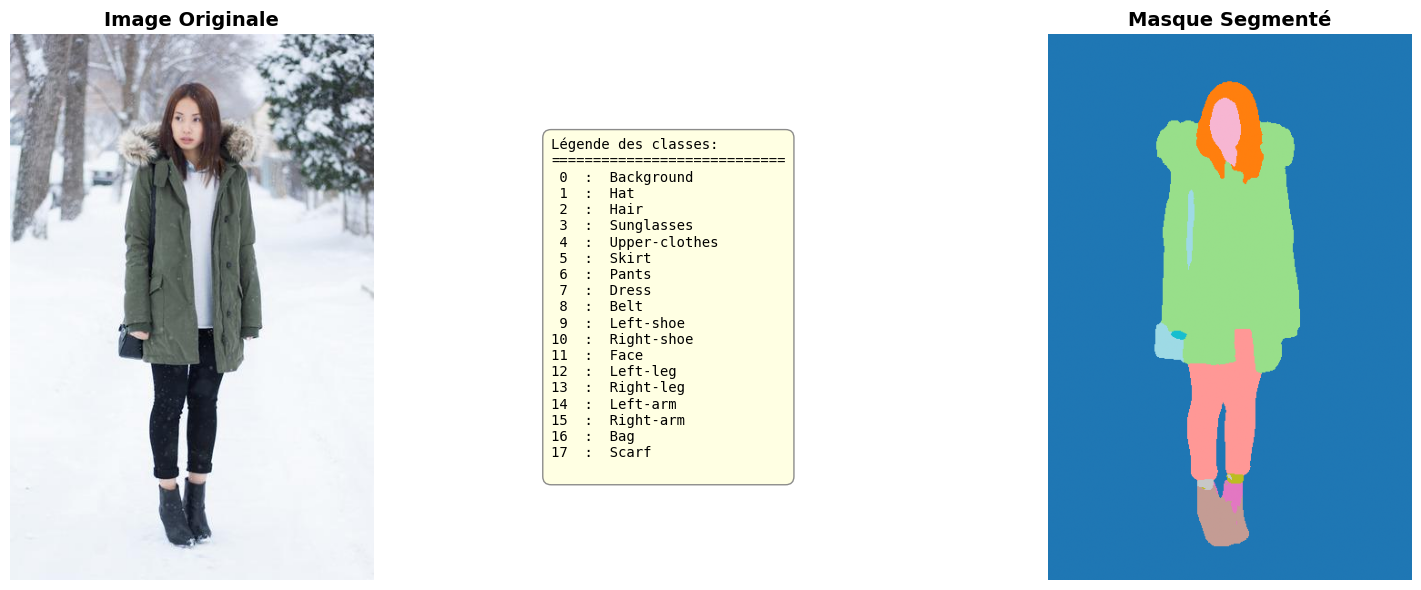

In [ ]:

if image_paths:
    single_image_path = image_paths[0]  # Prenons la première image de notre liste
    full_path = os.path.join(image_dir, single_image_path)
    print(f"Traitement de l'image : {full_path}")

    try:             
        # 2. Ouvrir l'image en mode binaire et lire son contenu
        with open(full_path, "rb") as f:
            image_data = f.read()
        print(f"Image lue : {len(image_data)} bytes")

        # 3. Déterminer le Content-Type
        content_type, _ = mimetypes.guess_type(full_path)
        if content_type is None:
            content_type = "image/png"  # Par défaut
        print(f"Content-Type détecté : {content_type}")

        # 4. Envoyer la requête POST à l'API
        request_headers = {"Content-Type": content_type, **headers}
        response = requests.post(API_URL, headers=request_headers, data=image_data)
        
        # 5. Vérifier le code de statut
        response.raise_for_status()
        print(f"Réponse API reçue (status {response.status_code})")

        # 6. Convertir la réponse JSON
        output = response.json()
        print(f"Masques détectés : {len(output)} classe(s)")

        # 7. Obtenir le masque final
        width, height = get_image_dimensions(full_path)
        combined_mask = create_masks(output, width, height)
        print(f"Masque combiné créé : {combined_mask.shape}")

        # 8. Afficher l'image originale et le masque segmenté
        original_image = Image.open(full_path)

        # Créer un seul grid 1x3 et utiliser ses axes (évite le warning tight_layout)
        fig, axes = plt.subplots(1, 3, figsize=(16, 6))

        # Image originale (gauche)
        axes[0].imshow(original_image)
        axes[0].set_title("Image Originale", fontsize=14, fontweight='bold')
        axes[0].axis("off")

        # Légende (centre) — texte centré dans la cellule du milieu
        axes[1].axis("off")
        legend_text = "Légende des classes:\n" + "="*28 + "\n"
        for label, class_id in CLASS_MAPPING.items():
            legend_text += f"{class_id:2d}  :  {label}\n"

        axes[1].text(0.2, 0.5, legend_text, fontsize=10, family='monospace',
                     verticalalignment='center', horizontalalignment='left',
                     bbox=dict(boxstyle='round', facecolor='lightyellow',
                               edgecolor='gray', linewidth=1.0, alpha=0.9, pad=0.6))

        # Masque segmenté (droite)
        axes[2].imshow(combined_mask, cmap="tab20")
        axes[2].set_title("Masque Segmenté", fontsize=14, fontweight='bold')
        axes[2].axis("off")

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Une erreur est survenue : {e}")
else:
    print("Aucune image à traiter. Vérifiez la configuration de 'image_dir' et 'max_images'.")

## 5. Segmentation de Plusieurs Images (Batch)

Maintenant que nous savons comment traiter une image, nous pouvons créer une fonction pour en traiter plusieurs.
Cette fonction va boucler sur la liste `image_paths` et appliquer la logique de segmentation à chaque image.
Nous utiliserons `tqdm` pour avoir une barre de progression.

In [ ]:
#max_images = 50
waiting = 1.0  # secondes entre les requêtes pour éviter throttling
REQUEST_TIMEOUT = 30        # secondes pour la connexion + lecture
REQUEST_RETRIES = 3         # nombre de tentatives en cas d'erreur réseau/timeouts
RETRY_BACKOFF = 5.0         # secondes multipliées par (attempt) pour backoff

def segment_images_batch(list_of_image_paths):
    """
    Segmente une liste d'images en utilisant l'API Hugging Face.

    Args:
        list_of_image_paths (list): Liste des noms de fichiers (dans image_dir).

    Returns:
        list: Liste des masques de segmentation (tableaux NumPy) ou None en cas d'erreur.
    """
    
    batch_segmentations = []

    # limiter le nombre d'images traitées
    to_process = list_of_image_paths[:max_images] if max_images else list_of_image_paths

    for img_name in tqdm(to_process, desc="Segmentation en batch"):
        full_path = os.path.join(image_dir, img_name)
        try:
            # lire l'image en binaire
            with open(full_path, "rb") as f:
                image_data = f.read()

            # déterminer le content-type
            content_type, _ = mimetypes.guess_type(full_path)
            if content_type is None:
                content_type = "image/png"

            # envoyer la requête
            request_headers = {"Content-Type": content_type, **headers}
            
            # retry loop avec timeout
            success = False
            last_exc = None
            for attempt in range(1, REQUEST_RETRIES + 1):
                try:
                    response = requests.post(API_URL, headers=request_headers, data=image_data, timeout=REQUEST_TIMEOUT)
                    response.raise_for_status()
                    output = response.json()
                    width, height = get_image_dimensions(full_path)
                    combined_mask = create_masks(output, width, height)
                    batch_segmentations.append(combined_mask)
                    success = True
                    break
                except requests.exceptions.Timeout as te:
                    last_exc = te
                    print(f"Timeout pour '{img_name}' (attempt {attempt}/{REQUEST_RETRIES}).")
                except requests.exceptions.RequestException as re:
                    last_exc = re
                    print(f"Erreur réseau pour '{img_name}' (attempt {attempt}/{REQUEST_RETRIES}): {re}")
                    # si c'est une erreur 4xx non-retriable, on sort
                    if isinstance(re, requests.exceptions.HTTPError) and re.response is not None and 400 <= re.response.status_code < 500:
                        break
                # backoff avant la prochaine tentative
                if attempt < REQUEST_RETRIES:
                    time.sleep(RETRY_BACKOFF * attempt)

            if not success:
                print(f"Échec après {REQUEST_RETRIES} tentatives pour '{img_name}': {last_exc}")
                batch_segmentations.append(None)

        except Exception as e:
            print(f"Erreur pour '{img_name}': {e}")
            batch_segmentations.append(None)

        # petite pause pour limiter la charge / éviter throttling
        time.sleep(waiting)

    return batch_segmentations


# Appeler la fonction pour segmenter les images listées dans image_paths
if image_paths:
    print(f"\nTraitement de {min(len(image_paths), max_images) if max_images else len(image_paths)} image(s) en batch...")
    batch_seg_results = segment_images_batch(image_paths)
    print("Traitement en batch terminé.")
else:
    batch_seg_results = []
    print("Aucune image à traiter en batch.")


Traitement de 2 image(s) en batch...


Segmentation en batch:   0%|          | 0/2 [00:00<?, ?it/s]

Traitement en batch terminé.


## 6. Affichage des Résultats en Batch

Nous allons maintenant créer une fonction pour afficher les images originales et leurs segmentations correspondantes côte à côte, dans une grille.


Affichage de 2 image(s) segmentée(s)...




In [ ]:
def display_segmented_images_batch(original_image_paths, segmentation_masks):
    """
    Affiche les images originales et leurs masques segmentés côte à côte dans une grille.
    Avec la légende au milieu, couleurs personnalisées et carrés de couleur.
    """
    # Définir les couleurs
    CLASS_COLORS = {
        "Background": "#000000", "Hat": "#FF0000", "Hair": "#FFA500",
        "Sunglasses": "#FFFF00", "Upper-clothes": "#00FF00", "Skirt": "#00FFFF",
        "Pants": "#0000FF", "Dress": "#FF00FF", "Belt": "#800080",
        "Left-shoe": "#FFC0CB", "Right-shoe": "#A52A2A", "Face": "#FFD700",
        "Left-leg": "#90EE90", "Right-leg": "#87CEEB", "Left-arm": "#DEB887",
        "Right-arm": "#F0E68C", "Bag": "#696969", "Scarf": "#DC143C"
    }
    
    # Créer la colormap DANS LE BON ORDRE (par class_id)
    num_classes = len(CLASS_MAPPING)
    colors = []
    
    # Construire la liste dans l'ordre des class_id (0, 1, 2, ...)
    for class_id in range(num_classes):
        # Trouver le label pour cet ID
        label = [k for k, v in CLASS_MAPPING.items() if v == class_id][0]
        colors.append(CLASS_COLORS[label])
    
    custom_cmap = ListedColormap(colors)
    
    num_images = max_images
    fig, axes = plt.subplots(num_images, 3, figsize=(8, 5 * num_images))
    
    if num_images == 1:
        axes = axes.reshape(1, -1)
    
    for idx, (img_path, mask) in enumerate(zip(original_image_paths, segmentation_masks)):
        full_path = os.path.join(image_dir, img_path)
        
        try:
            original_image = Image.open(full_path)
            
            # Image originale
            axes[idx, 0].imshow(original_image)
            axes[idx, 0].set_title(f"Image Originale: {img_path}", fontsize=12, fontweight='bold')
            axes[idx, 0].axis("off")
            
            # Légende avec couleurs
            axes[idx, 1].axis("off")
            
            # Créer les éléments texte avec couleur pour chaque classe
            legend_artists = []
            for label, class_id in sorted(CLASS_MAPPING.items(), key=lambda x: x[1]):
                color_hex = CLASS_COLORS[label]
                legend_artists.append(plt.Line2D([0], [0], marker='s', color='w', 
                                                markerfacecolor=color_hex, markersize=10, 
                                                label=f"{class_id}: {label}"))
            
            # Afficher la légende avec les carrés de couleur
            axes[idx, 1].legend(handles=legend_artists, loc='center', fontsize=8,
                               frameon=True, fancybox=True, shadow=True)
            
            # Masque avec couleurs personnalisées
            if mask is not None:
                im = axes[idx, 2].imshow(mask, cmap=custom_cmap, vmin=0, vmax=num_classes-1)
                axes[idx, 2].set_title("Masque Segmenté", fontsize=12, fontweight='bold')
                axes[idx, 2].axis("off")
            else:
                axes[idx, 2].text(0.5, 0.5, "Erreur", ha='center', va='center', fontsize=12, color='red')
                axes[idx, 2].axis("off")
                
        except Exception as e:
            print(f"Erreur : {e}")
            axes[idx, 0].axis("off")
            axes[idx, 1].axis("off")
            axes[idx, 2].axis("off")
    
    plt.tight_layout()
    plt.show()


# Afficher les résultats du batch
if batch_seg_results and any(m is not None for m in batch_seg_results):
    print(f"\nAffichage de {len([m for m in batch_seg_results if m is not None])} image(s) segmentée(s)...")
    display_segmented_images_batch(image_paths, batch_seg_results)
else:
    print("Aucun résultat de segmentation à afficher.")

## Conclusion et Prochaines Étapes

Félicitations ! Vous avez appris à :
- Configurer les appels à l'API d'inférence Hugging Face.
- Envoyer des images pour la segmentation.
- Interpréter les résultats (avec l'aide des fonctions fournies).
- Visualiser les segmentations.

Pistes d'amélioration ou d'exploration :
- **Gestion d'erreurs plus fine** : Implémenter des tentatives multiples (retry) en cas d'échec de l'API (par exemple, si le modèle est en cours de chargement).
- **Appels asynchrones** : Pour un grand nombre d'images, des appels asynchrones (avec `asyncio` et `aiohttp`) seraient beaucoup plus rapides.
- **Autres modèles** : Explorer d'autres modèles de segmentation ou d'autres tâches sur Hugging Face Hub.

N'hésitez pas à modifier le code, à tester avec vos propres images et à explorer davantage !

**_Note_** : Si vous aimez ce modèle, n'hésitez pas à le [télécharger](https://huggingface.co/sayeed99/segformer_b3_clothes) et jouer avec directement sur votre machine !

---
## test via la méthode asynchrone

In [ ]:
#-------------RuntimeError: asyncio.run() cannot be called from a running event loop
#Cause : vous êtes dans un environnement (Jupyter / VS Code interactive) qui a déjà une boucle d'événements asyncio en cours. asyncio.run() crée et gère sa propre boucle, d'où l'erreur.


max_images = 50

async def segment_images_batch_async(list_of_image_paths):
    """
    Segmente une liste d'images en utilisant l'API Hugging Face de manière asynchrone.

    Args:
        list_of_image_paths (list): Liste des noms de fichiers (dans image_dir).

    Returns:
        list: Liste des masques de segmentation (tableaux NumPy) ou None en cas d'erreur.
    """
    
    async def process_image(session, img_name, semaphore):
        """Traite une seule image de manière asynchrone"""
        async with semaphore:  # Limiter les requêtes simultanées
            full_path = os.path.join(image_dir, img_name)
            try:
                # lire l'image en binaire
                with open(full_path, "rb") as f:
                    image_data = f.read()

                # déterminer le content-type
                content_type, _ = mimetypes.guess_type(full_path)
                if content_type is None:
                    content_type = "image/png"

                # envoyer la requête asynchrone
                request_headers = {"Content-Type": content_type, **headers}
                async with session.post(API_URL, headers=request_headers, data=image_data) as response:
                    response.raise_for_status()
                    output = await response.json()
                    width, height = get_image_dimensions(full_path)
                    combined_mask = create_masks(output, width, height)
                    
                    # Petite pause entre les requêtes pour éviter le throttling
                    await asyncio.sleep(5)
                    
                    return combined_mask

            except Exception as e:
                print(f"Erreur pour '{img_name}': {e}")
                return None
    
    batch_segmentations = []
    
    # limiter le nombre d'images traitées
    to_process = list_of_image_paths[:max_images] if max_images else list_of_image_paths
    
    # Ajuster le nombre de requêtes simultanées selon max_images
    if max_images > 30:
        concurrent_limit = 2  # Pour éviter de surcharger avec beaucoup d'images
    else:
        concurrent_limit = 3
    
    print(f"Limite de requêtes simultanées : {concurrent_limit}")
    
    # Limiter les requêtes simultanées
    semaphore = asyncio.Semaphore(concurrent_limit)
    
    # Créer une session avec limite de connexions
    connector = aiohttp.TCPConnector(limit=concurrent_limit)
    async with aiohttp.ClientSession(connector=connector) as session:
        # Créer les tâches asynchrones
        tasks = [process_image(session, img_name, semaphore) for img_name in to_process]
        
        # Exécuter toutes les tâches et afficher la progression
        for coro in tqdm(asyncio.as_completed(tasks), total=len(tasks), desc="Segmentation en batch"):
            result = await coro
            batch_segmentations.append(result)
    
    return batch_segmentations


# Appeler la fonction pour segmenter les images listées dans image_paths
if image_paths:
    print(f"\nTraitement asynchrone de {min(len(image_paths), max_images) if max_images else len(image_paths)} image(s) en batch...")
    batch_seg_results = asyncio.run(segment_images_batch_async(image_paths))
    print("Traitement en batch terminé.")
else:
    batch_seg_results = []
    print("Aucune image à traiter en batch.")


Traitement asynchrone de 50 image(s) en batch...


RuntimeError: asyncio.run() cannot be called from a running event loop

### Rapport Synthétique sur les Performances du Modèle

In [ ]:
def generate_performance_report(batch_seg_results):
    total_images = len(batch_seg_results)
    successful_segmentations = sum(1 for mask in batch_seg_results if mask is not None)
    success_rate = (successful_segmentations / total_images) * 100
    
    print("Rapport de Performance du Modèle")
    print(f"Total d'images traitées : {total_images}")
    print(f"Images segmentées avec succès : {successful_segmentations}")
    print(f"Taux de réussite : {success_rate:.2f}%")

perf=generate_performance_report(batch_seg_results)


NameError: name 'batch_seg_results' is not defined

## Constitution de Jeux de Données

- **Jeu d'entraînement** : 70% des données (35 images).
- **Jeu de validation** : 15% des données (7 images).
- **Jeu de test** : 15% des données (8 images).

## Évaluation du Modèle

Choix d’une Métrique Pertinente

- **IoU (Intersection over Union)** : Mesure la précision de la segmentation.
- **Dice Score** : Mesure la similarité entre deux ensembles.
- **F1 Score** : Équilibre entre précision et rappel.



#### 1er Try

In [ ]:
from sklearn.metrics import jaccard_score, f1_score

def evaluate_model(original_image_paths, predicted_masks):
    iou_scores = []
    f1_scores = []
    
    for idx,(img_path, pred_mask) in enumerate(zip(original_image_paths, predicted_masks)):
        full_path = os.path.join(image_dir, img_path)
        #original_image = Image.open(full_path)
        with open(full_path, "rb") as f:
            image_data = f.read()
        # Calculer IoU
        iou = jaccard_score(image_data, pred_mask.flatten(), average='macro')
        iou_scores.append(iou)
        
        # Calculer F1 Score
        f1 = f1_score(image_data, pred_mask.flatten(), average='macro')
        f1_scores.append(f1)
    
    print(f"IoU moyen : {sum(iou_scores) / len(iou_scores):.2f}")
    print(f"F1 Score moyen : {sum(f1_scores) / len(f1_scores):.2f}")

# Appel de la fonction avec les masques de vérité terrain et les masques prédits
evaluate_model(image_paths, batch_seg_results)  # Remplacez ground_truth_masks par vos masques réels

FileNotFoundError: [Errno 2] No such file or directory: './Mask\\image_9.png'

#### 2éme Try

In [ ]:
def evaluate_model(ground_truth_mask_paths, predicted_masks):
    """
    Évalue les masques prédits contre les masques de vérité terrain
    
    Args:
        ground_truth_mask_paths: liste des chemins vers les masques GT
        predicted_masks: liste des masques prédits (numpy arrays)
    """
    iou_scores = []
    f1_scores = []
    
    for idx, (gt_path, pred_mask) in enumerate(zip(ground_truth_mask_paths, predicted_masks)):
        # Charger le masque de vérité terrain
        gt_mask = Image.open(gt_path)
        gt_mask = np.array(gt_mask)
        
        # S'assurer que les masques sont en format binaire (0 ou 1)
        gt_mask_flat = (gt_mask > 0).astype(int).flatten()
        pred_mask_flat = (pred_mask > 0).astype(int).flatten()
        
        # Vérifier que les dimensions correspondent
        if gt_mask_flat.shape != pred_mask_flat.shape:
            print(f"Attention: dimensions différentes pour l'image {idx}")
            continue
        
        # Calculer IoU (Jaccard)
        iou = jaccard_score(gt_mask_flat, pred_mask_flat, average='binary')
        iou_scores.append(iou)
        
        # Calculer F1 Score
        f1 = f1_score(gt_mask_flat, pred_mask_flat, average='binary')
        f1_scores.append(f1)
    
    print(f"IoU moyen : {np.mean(iou_scores):.4f}")
    print(f"F1 Score moyen : {np.mean(f1_scores):.4f}")
    
    return iou_scores, f1_scores

#-------------------------------------------
mask_dir = "./Mask"
mask_file= [f for f in os.listdir(mask_dir) if os.path.isfile(os.path.join(mask_dir, f))]
print("Images à traiter:", mask_file)
mask_paths = []
for fname in mask_file:
    full = os.path.join(mask_dir, fname)
    mask_paths.append(full)
print("Masques de vérité terrain:", mask_paths)

evaluate_model(mask_paths, batch_seg_results)


Images à traiter: ['mask_0.png', 'mask_1.png', 'mask_10.png', 'mask_11.png', 'mask_12.png', 'mask_13.png', 'mask_14.png', 'mask_15.png', 'mask_16.png', 'mask_17.png', 'mask_18.png', 'mask_19.png', 'mask_2.png', 'mask_20.png', 'mask_21.png', 'mask_22.png', 'mask_23.png', 'mask_24.png', 'mask_25.png', 'mask_26.png', 'mask_27.png', 'mask_28.png', 'mask_29.png', 'mask_3.png', 'mask_30.png', 'mask_31.png', 'mask_32.png', 'mask_33.png', 'mask_34.png', 'mask_35.png', 'mask_36.png', 'mask_37.png', 'mask_38.png', 'mask_39.png', 'mask_4.png', 'mask_40.png', 'mask_41.png', 'mask_42.png', 'mask_43.png', 'mask_44.png', 'mask_45.png', 'mask_46.png', 'mask_47.png', 'mask_48.png', 'mask_49.png', 'mask_5.png', 'mask_6.png', 'mask_7.png', 'mask_8.png', 'mask_9.png']
Masques de vérité terrain: ['./Mask\\mask_0.png', './Mask\\mask_1.png', './Mask\\mask_10.png', './Mask\\mask_11.png', './Mask\\mask_12.png', './Mask\\mask_13.png', './Mask\\mask_14.png', './Mask\\mask_15.png', './Mask\\mask_16.png', './Mask\

([0.9510295468462951, 0.9238261774354379],
 [0.9749001991113553, 0.9604050389489419])